# 02 - Stationary Field Simulation

This notebook presents the full baseline analysis for **random**, **fine lawnmower**, and **coarse lawnmower** sampling before moving to active sampling in Notebook 03.

## Goals implemented here
- Fine vs coarse lawnmower baseline paths
- Same stationary 2D GP fit for each baseline
- Fair metric comparison (RMSE, mean variance, path length, learned hyperparameters)
- Calibration diagnostics (error vs uncertainty, coverage, standardized residuals)
- 3D surface comparison (true field vs GP reconstruction)

We assume noisy measurements from a hidden field:

$$y_i = f(x_i, y_i) + \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0,\sigma_n^2)$$

In [32]:
# -----------------------------
# 0) Imports and project wiring
# -----------------------------

import os
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import gpytorch

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.fields import create_grid, get_field, sample_noisy_measurements
from src.samplers import random_sampler
from src.metrics import path_length
from src.plotting import plot_field_with_samples

torch.set_default_dtype(torch.float32)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'PyTorch device: {device}')
print('Imports loaded successfully.')

PyTorch device: cpu
Imports loaded successfully.


## 1) Configure Simulation

Set common parameters shared by all baselines so differences come from the **sampling path**, not model configuration.

We configure:
- Grid resolution and sample budget
- Noise level
- Field type
- Fine and coarse lawnmower strides
- Shared GP training settings

In [33]:
# -----------------------------
# 1) Simulation configuration
# -----------------------------

seed = 7
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

# Grid and sampling settings
grid_size = 50
n_samples = 120
noise_std = 0.05
field_name = 'temperature'

# Fine/coarse lawnmower stride settings
fine_row_stride = 1
fine_column_stride = 1
coarse_row_stride = 4
coarse_column_stride = 4

# Shared GP settings for fair comparison
gp_train_iters = 180
gp_learning_rate = 0.10

x, y, x1, x2, x_test = create_grid(grid_size=grid_size)
field = get_field(field_name, x1, x2)

print(f'Grid size: {grid_size}x{grid_size} ({len(x_test)} points)')
print(f'Sample budget: {n_samples}')
print(f'Noise std: {noise_std}')
print(f'Field type: {field_name}')
print(f'Fine stride: row={fine_row_stride}, col={fine_column_stride}')
print(f'Coarse stride: row={coarse_row_stride}, col={coarse_column_stride}')

Grid size: 50x50 (2500 points)
Sample budget: 120
Noise std: 0.05
Field type: temperature
Fine stride: row=1, col=1
Coarse stride: row=4, col=4


## 2) Generate Baseline Sample Paths

We compare three baseline trajectories:
1. Random sampling
2. Fine lawnmower sweep
3. Coarse lawnmower sweep

Path cost is computed as:

$$c(P) = \sum_{i=1}^{N-1}\|x_{i+1} - x_i\|$$

This approximates travel effort for a stop-and-sample robot.

In [34]:
# -----------------------------
# 2) Baseline path generation
# -----------------------------

def lawnmower_with_stride(x_axis, y_axis, n_samples, row_stride=1, column_stride=1):
    """Build a row-wise lawnmower path using configurable row/column stride."""
    x_sub = x_axis[::max(1, int(column_stride))]
    y_sub = y_axis[::max(1, int(row_stride))]

    points = []
    for row_idx, y_val in enumerate(y_sub):
        row_x = x_sub if row_idx % 2 == 0 else x_sub[::-1]
        for x_val in row_x:
            points.append((x_val, y_val))

    path = np.array(points, dtype=float)
    if len(path) < n_samples:
        raise ValueError(
            f'Not enough points for n_samples={n_samples}. Increase grid size or reduce stride.'
        )
    return path[:n_samples]

random_points = random_sampler(x_test, n_samples=n_samples, rng=rng)
fine_lawnmower_points = lawnmower_with_stride(
    x, y, n_samples=n_samples, row_stride=fine_row_stride, column_stride=fine_column_stride
)
coarse_lawnmower_points = lawnmower_with_stride(
    x, y, n_samples=n_samples, row_stride=coarse_row_stride, column_stride=coarse_column_stride
)

random_cost = path_length(random_points)
fine_lawnmower_cost = path_length(fine_lawnmower_points)
coarse_lawnmower_cost = path_length(coarse_lawnmower_points)

print(f'Random path length: {random_cost:.3f}')
print(f'Fine lawnmower path length: {fine_lawnmower_cost:.3f}')
print(f'Coarse lawnmower path length: {coarse_lawnmower_cost:.3f}')

Random path length: 64.012
Fine lawnmower path length: 2.429
Coarse lawnmower path length: 9.714


## 3) Sample Noisy Measurements

For each path, collect clean field values and noisy measurements with the same noise model.

In [35]:
# -----------------------------
# 3) Simulate noisy sensor readings
# -----------------------------

random_clean, random_noisy = sample_noisy_measurements(
    field, random_points, noise_std=noise_std, rng=rng
)
fine_clean, fine_noisy = sample_noisy_measurements(
    field, fine_lawnmower_points, noise_std=noise_std, rng=rng
)
coarse_clean, coarse_noisy = sample_noisy_measurements(
    field, coarse_lawnmower_points, noise_std=noise_std, rng=rng
)

print('Noisy sample statistics (mean +/- std):')
print(f"  Random: {random_noisy.mean():.3f} +/- {random_noisy.std():.3f}")
print(f"  Fine lawnmower: {fine_noisy.mean():.3f} +/- {fine_noisy.std():.3f}")
print(f"  Coarse lawnmower: {coarse_noisy.mean():.3f} +/- {coarse_noisy.std():.3f}")

Noisy sample statistics (mean +/- std):
  Random: 0.277 +/- 0.262
  Fine lawnmower: 0.161 +/- 0.104
  Coarse lawnmower: 0.260 +/- 0.254


## 4) Plot True Field with Sampled Points

Visual comparison of spatial coverage for random, fine lawnmower, and coarse lawnmower paths.

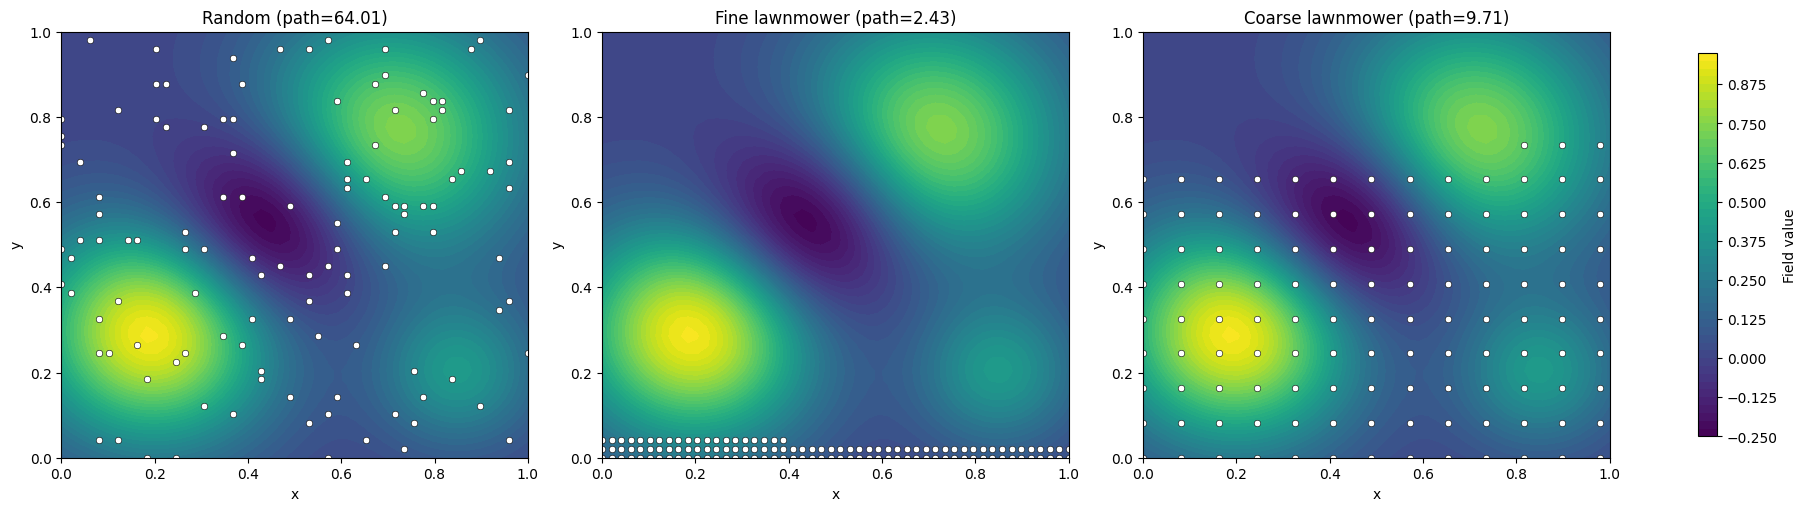

In [36]:
# -----------------------------
# 4) Field maps with sampled points
# -----------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

c0 = plot_field_with_samples(
    axes[0], x1, x2, field, random_points,
    title=f'Random (path={random_cost:.2f})'
 )
c1 = plot_field_with_samples(
    axes[1], x1, x2, field, fine_lawnmower_points,
    title=f'Fine lawnmower (path={fine_lawnmower_cost:.2f})'
 )
c2 = plot_field_with_samples(
    axes[2], x1, x2, field, coarse_lawnmower_points,
    title=f'Coarse lawnmower (path={coarse_lawnmower_cost:.2f})'
 )

fig.colorbar(c2, ax=axes.ravel().tolist(), shrink=0.9, label='Field value')
plt.show()

## 5) Baseline Path-Length Comparison

A shorter path is usually operationally easier, but reconstruction quality still matters.

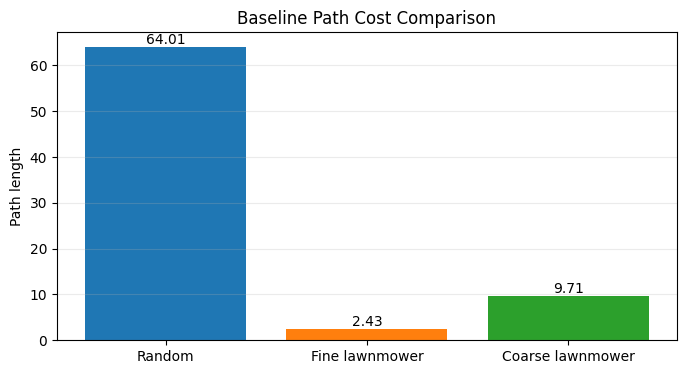

In [37]:
# -----------------------------
# 5) Compare travel cost
# -----------------------------

labels = ['Random', 'Fine lawnmower', 'Coarse lawnmower']
values = [random_cost, fine_lawnmower_cost, coarse_lawnmower_cost]

plt.figure(figsize=(8, 4))
bars = plt.bar(labels, values, color=['tab:blue', 'tab:orange', 'tab:green'])
plt.ylabel('Path length')
plt.title('Baseline Path Cost Comparison')
plt.grid(axis='y', alpha=0.25)

for b in bars:
    yv = b.get_height()
    plt.text(
        b.get_x() + b.get_width() / 2,
        yv,
        f'{yv:.2f}',
        ha='center',
        va='bottom'
    )

plt.show()

## 6) Fit the Same Stationary GP to Each Baseline

This section keeps GP architecture and training settings fixed across strategies.

Tracked outputs per strategy:
- RMSE on full evaluation grid
- Mean predictive variance
- Path length
- Learned length scale
- Learned noise variance

We use an Exact GP with ConstantMean + RBF kernel (ARD over 2D inputs).

In [38]:
# -----------------------------
# 6) Shared GP fit and baseline comparison
# -----------------------------

class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(ard_num_dims=2)
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)


def fit_gp_and_predict(sample_points, noisy_values):
    train_x = torch.tensor(sample_points, dtype=torch.float32, device=device)
    train_y = torch.tensor(noisy_values, dtype=torch.float32, device=device)
    test_x = torch.tensor(x_test, dtype=torch.float32, device=device)

    likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
    model = ExactGPModel(train_x, train_y, likelihood).to(device)

    model.train()
    likelihood.train()

    optimizer = torch.optim.Adam(model.parameters(), lr=gp_learning_rate)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

    for _ in range(gp_train_iters):
        optimizer.zero_grad()
        output = model(train_x)
        loss = -mll(output, train_y)
        loss.backward()
        optimizer.step()

    model.eval()
    likelihood.eval()
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        pred_dist = likelihood(model(test_x))
        pred_mean = pred_dist.mean.detach().cpu().numpy()
        pred_var = pred_dist.variance.detach().cpu().numpy()

    lengthscale = float(model.covar_module.base_kernel.lengthscale.detach().mean().cpu().item())
    noise_variance = float(likelihood.noise.detach().cpu().item())

    return {
        'mean': pred_mean,
        'var': pred_var,
        'std': np.sqrt(np.maximum(pred_var, 1e-12)),
        'lengthscale': lengthscale,
        'noise_variance': noise_variance,
    }


def evaluate_strategy(name, sample_points, noisy_values, path_cost):
    pred = fit_gp_and_predict(sample_points, noisy_values)
    true_flat = field.ravel()

    rmse = float(np.sqrt(np.mean((pred['mean'] - true_flat) ** 2)))
    mean_var = float(np.mean(pred['var']))
    abs_error = np.abs(pred['mean'] - true_flat)
    corr = float(np.corrcoef(abs_error, pred['std'])[0, 1])

    lower = pred['mean'] - 1.96 * pred['std']
    upper = pred['mean'] + 1.96 * pred['std']
    coverage_95 = float(np.mean((true_flat >= lower) & (true_flat <= upper)))

    z = (true_flat - pred['mean']) / np.maximum(pred['std'], 1e-8)
    z_mean = float(np.mean(z))

    return {
        'name': name,
        'n_samples': int(len(sample_points)),
        'path_length': float(path_cost),
        'rmse': rmse,
        'mean_variance': mean_var,
        'lengthscale': pred['lengthscale'],
        'noise_variance': pred['noise_variance'],
        'error_uncert_corr': corr,
        'coverage_95': coverage_95,
        'z_mean': z_mean,
        'mean': pred['mean'],
        'var': pred['var'],
        'std': pred['std'],
        'abs_error': abs_error,
        'points': sample_points,
    }


results = [
    evaluate_strategy('Random', random_points, random_noisy, random_cost),
    evaluate_strategy('Fine lawnmower', fine_lawnmower_points, fine_noisy, fine_lawnmower_cost),
    evaluate_strategy('Coarse lawnmower', coarse_lawnmower_points, coarse_noisy, coarse_lawnmower_cost),
]

summary_df = pd.DataFrame([
    {
        'Strategy': r['name'],
        'Samples': r['n_samples'],
        'Path Length': r['path_length'],
        'RMSE': r['rmse'],
        'Mean Variance': r['mean_variance'],
        'Length Scale': r['lengthscale'],
        'Noise Variance': r['noise_variance'],
        'Err-Unc Corr': r['error_uncert_corr'],
        'Coverage95': r['coverage_95'],
        'Mean z': r['z_mean'],
    }
    for r in results
])

summary_df = summary_df.sort_values('RMSE').reset_index(drop=True)
summary_df

,Strategy,Samples,Path Length,RMSE,Mean Variance,Length Scale,Noise Variance,Err-Unc Corr,Coverage95,Mean z
0,Random,120,64.011687,0.026404,0.003012,0.212037,0.002097,0.380209,1.0000,0.021189
1,Coarse lawnmower,120,9.714286,0.048628,0.011328,0.224060,0.002261,0.771211,1.0000,0.067867
2,Fine lawnmower,120,2.428571,0.281282,0.012875,0.136263,0.002254,0.327570,0.6576,1.156492


## 7) Calibration Diagnostics: Error vs Predicted Uncertainty

A useful GP should express higher uncertainty where prediction error is larger.

For each strategy we inspect:
- Scatter of absolute error vs predictive standard deviation
- Correlation between error and uncertainty
- Empirical 95% coverage
- Mean standardized residual

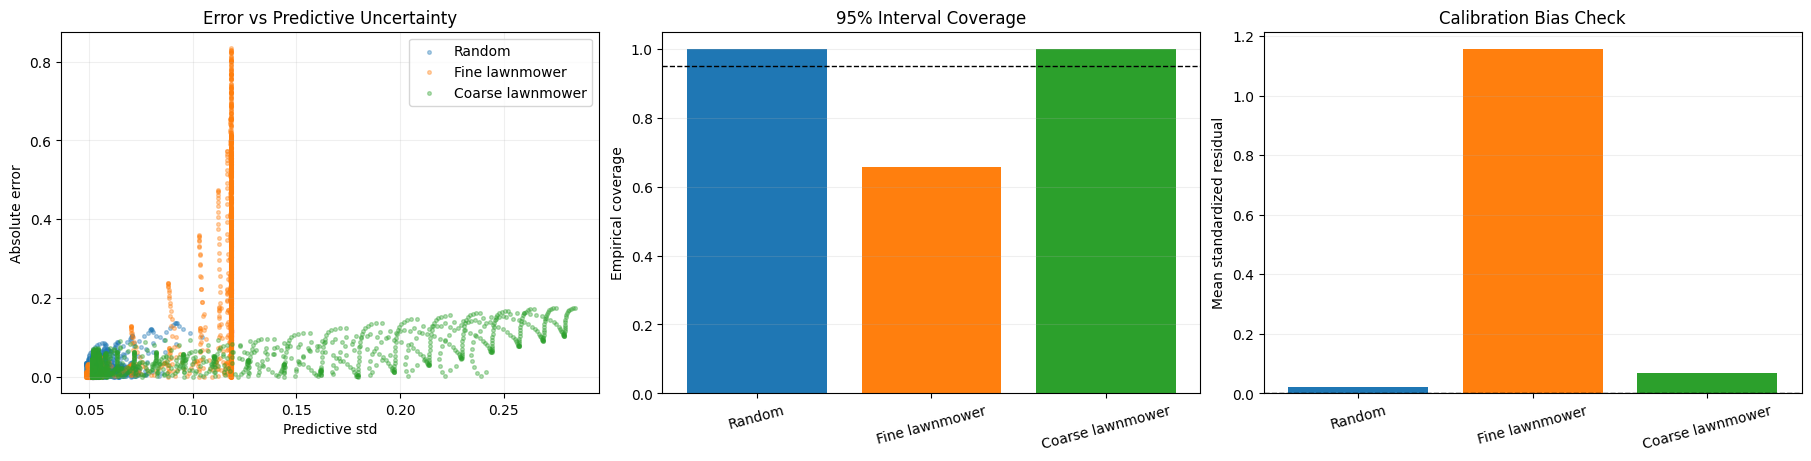

,Strategy,Err-Unc Corr,Coverage95,Mean z
0,Random,0.380209,1.0000,0.021189
1,Coarse lawnmower,0.771211,1.0000,0.067867
2,Fine lawnmower,0.327570,0.6576,1.156492


In [39]:
# -----------------------------
# 7) Calibration diagnostics plots
# -----------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)

for r in results:
    axes[0].scatter(r['std'], r['abs_error'], s=7, alpha=0.35, label=r['name'])
axes[0].set_xlabel('Predictive std')
axes[0].set_ylabel('Absolute error')
axes[0].set_title('Error vs Predictive Uncertainty')
axes[0].legend()
axes[0].grid(alpha=0.2)

x_pos = np.arange(len(results))
coverage_vals = [r['coverage_95'] for r in results]
axes[1].bar(x_pos, coverage_vals, color=['tab:blue', 'tab:orange', 'tab:green'])
axes[1].axhline(0.95, linestyle='--', color='black', linewidth=1)
axes[1].set_xticks(x_pos, [r['name'] for r in results], rotation=15)
axes[1].set_ylim(0.0, 1.05)
axes[1].set_ylabel('Empirical coverage')
axes[1].set_title('95% Interval Coverage')
axes[1].grid(axis='y', alpha=0.2)

z_means = [r['z_mean'] for r in results]
axes[2].bar(x_pos, z_means, color=['tab:blue', 'tab:orange', 'tab:green'])
axes[2].axhline(0.0, linestyle='--', color='black', linewidth=1)
axes[2].set_xticks(x_pos, [r['name'] for r in results], rotation=15)
axes[2].set_ylabel('Mean standardized residual')
axes[2].set_title('Calibration Bias Check')
axes[2].grid(axis='y', alpha=0.2)

plt.show()

summary_df[['Strategy', 'Err-Unc Corr', 'Coverage95', 'Mean z']]

## 8) 3D Surface Comparison

Side-by-side 3D surfaces let us compare shape reconstruction quality directly.

For each baseline we plot:
- True field surface
- GP posterior mean surface
- Absolute error surface

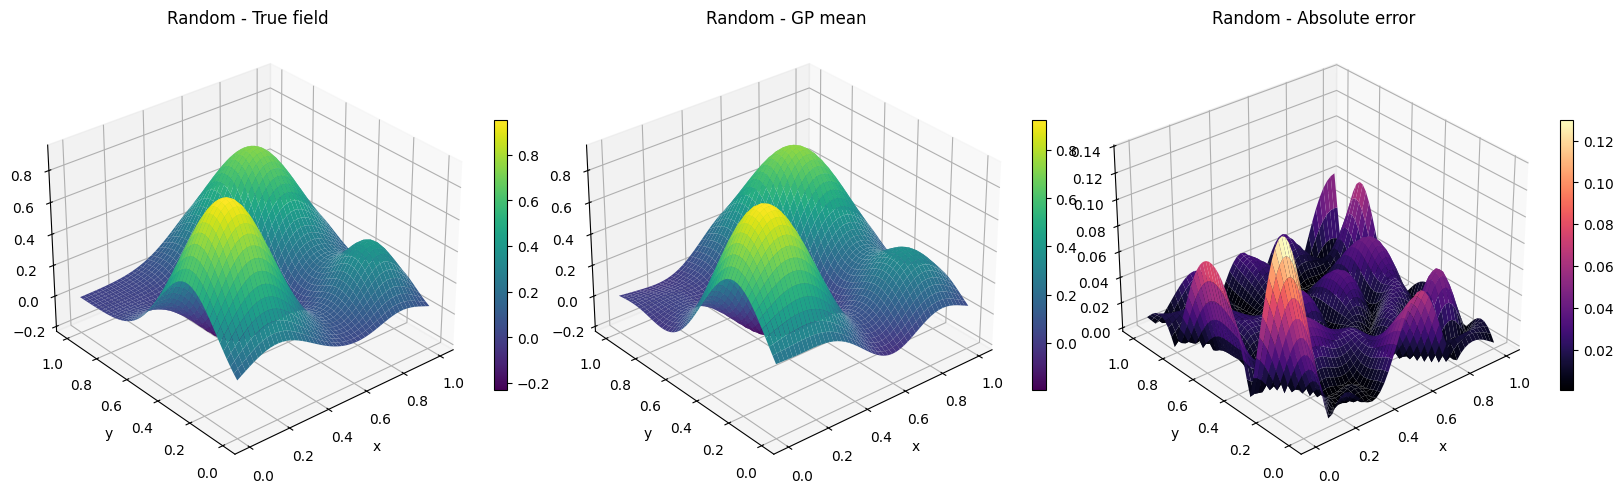

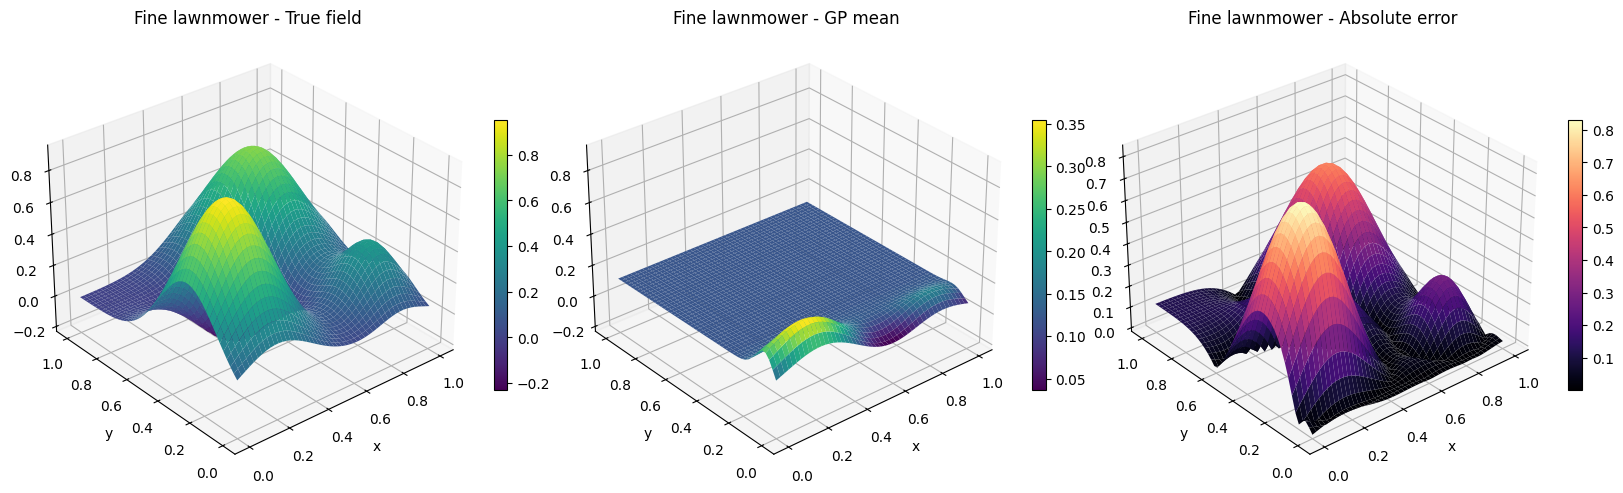

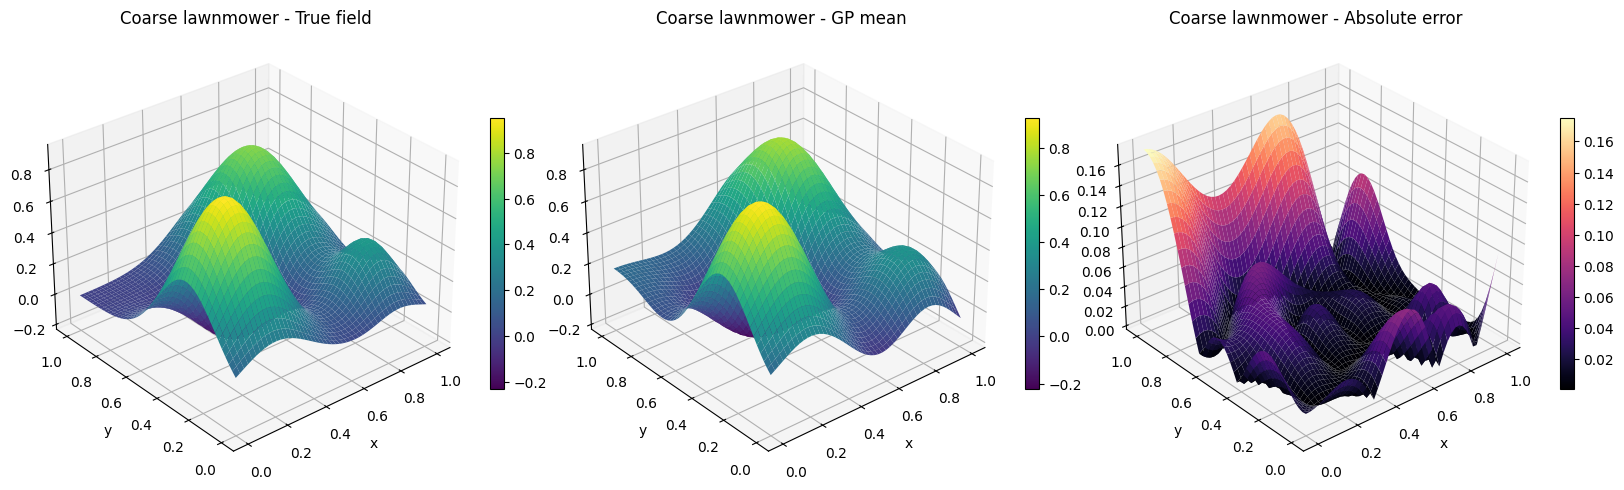

In [40]:
# -----------------------------
# 8) 3D surfaces: true vs GP mean vs error
# -----------------------------

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

for r in results:
    mean_grid = r['mean'].reshape(x1.shape)
    err_grid = r['abs_error'].reshape(x1.shape)

    fig = plt.figure(figsize=(16, 4.8), constrained_layout=True)
    ax1 = fig.add_subplot(1, 3, 1, projection='3d')
    ax2 = fig.add_subplot(1, 3, 2, projection='3d')
    ax3 = fig.add_subplot(1, 3, 3, projection='3d')

    surf1 = ax1.plot_surface(x1, x2, field, cmap='viridis', linewidth=0, antialiased=True)
    surf2 = ax2.plot_surface(x1, x2, mean_grid, cmap='viridis', linewidth=0, antialiased=True)
    surf3 = ax3.plot_surface(x1, x2, err_grid, cmap='magma', linewidth=0, antialiased=True)

    z_min = min(field.min(), mean_grid.min())
    z_max = max(field.max(), mean_grid.max())
    ax1.set_zlim(z_min, z_max)
    ax2.set_zlim(z_min, z_max)

    for ax in (ax1, ax2, ax3):
        ax.view_init(elev=30, azim=-130)
        ax.set_xlabel('x')
        ax.set_ylabel('y')

    ax1.set_title(f"{r['name']} - True field")
    ax2.set_title(f"{r['name']} - GP mean")
    ax3.set_title(f"{r['name']} - Absolute error")

    fig.colorbar(surf1, ax=ax1, shrink=0.6, pad=0.05)
    fig.colorbar(surf2, ax=ax2, shrink=0.6, pad=0.05)
    fig.colorbar(surf3, ax=ax3, shrink=0.6, pad=0.05)
    plt.show()

## 9) Notebook Summary

Completed in this notebook:
- Fine and coarse lawnmower variants
- GP regression for random/fine/coarse with matched settings
- RMSE, mean variance, path length, learned length scale, learned noise variance
- Calibration diagnostics (error-vs-uncertainty, correlation, 95% coverage, mean standardized residual)
- 3D true-field vs GP-mean (plus error surface)

Next step: implement greedy information placement and sequential active samplers in Notebook 03.